In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"F:\yingxiang2")
FINAL_COHORT_CSV = PROJECT_ROOT / "final_patients_egfr.csv"
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw" / "NSCLC Radiogenomics"

print("Project root:", PROJECT_ROOT)
print("Final cohort CSV exists:", FINAL_COHORT_CSV.exists())
print("Raw data directory exists:", RAW_DATA_DIR.exists())

Project root: F:\yingxiang2
Final cohort CSV exists: True
Raw data directory exists: True


In [2]:
df = pd.read_csv(FINAL_COHORT_CSV)

print("Rows:", len(df))
print("Columns:", list(df.columns))
display(df.head())

Rows: 97
Columns: ['Case ID', 'EGFR mutation status']


,Case ID,EGFR mutation status
0,R01-003,Mutant
1,R01-005,Wildtype
2,R01-006,Wildtype
3,R01-008,Wildtype
4,R01-012,Wildtype


In [3]:
print(df["EGFR mutation status"].value_counts(dropna=False))

print("\nMissing Case ID:", df["Case ID"].isna().sum())
print("Missing EGFR:", df["EGFR mutation status"].isna().sum())
print("Duplicate Case ID:", df["Case ID"].duplicated().sum())

EGFR mutation status
Wildtype    74
Mutant      23
Name: count, dtype: int64

Missing Case ID: 0
Missing EGFR: 0
Duplicate Case ID: 0


In [4]:
# 获取原始影像目录下所有患者文件夹名
raw_patient_dirs = {
    p.name for p in RAW_DATA_DIR.iterdir()
    if p.is_dir()
}

# 最终队列中的患者ID
cohort_ids = set(df["Case ID"].astype(str).str.strip())

# 匹配情况
matched_ids = sorted(cohort_ids & raw_patient_dirs)
missing_ids = sorted(cohort_ids - raw_patient_dirs)

print("Cohort patients:", len(cohort_ids))
print("Matched patient folders:", len(matched_ids))
print("Missing patient folders:", len(missing_ids))

if missing_ids:
    print("\nMissing IDs:")
    print(missing_ids)


Cohort patients: 97
Matched patient folders: 97
Missing patient folders: 0


In [5]:
example_id = df["Case ID"].iloc[0]
example_dir = RAW_DATA_DIR / example_id

print("Example patient:", example_id)
print("Path:", example_dir)

for p in example_dir.iterdir():
    print(p.name, "DIR" if p.is_dir() else "FILE")

Example patient: R01-003
Path: F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01-003
12-09-1991-NA-CT CHEST WO-02622 DIR
12-18-1991-NA-PET IMAGE WCT SKULL--72170 DIR


In [6]:
ct_dir = next(
    p for p in example_dir.iterdir()
    if p.is_dir() and "CT" in p.name.upper()
)

print("CT directory:")
print(ct_dir)

print("\nContents:")
for p in ct_dir.iterdir():
    print(p.name, "DIR" if p.is_dir() else "FILE")


CT directory:
F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01-003\12-09-1991-NA-CT CHEST WO-02622

Contents:
1000.000000-3D Slicer segmentation result-96510 DIR
4.000000-THIN LUNG WINDOW-69868 DIR


In [7]:
for subdir in ct_dir.iterdir():
    if subdir.is_dir():
        files = list(subdir.iterdir())
        print("\nFolder:", subdir.name)
        print("Number of files:", len(files))
        print("First 5 files:")
        for f in files[:5]:
            print("   ", f.name)


Folder: 1000.000000-3D Slicer segmentation result-96510
Number of files: 1
First 5 files:
    1-1.dcm

Folder: 4.000000-THIN LUNG WINDOW-69868
Number of files: 288
First 5 files:
    1-001.dcm
    1-002.dcm
    1-003.dcm
    1-004.dcm
    1-005.dcm


In [8]:
import pydicom

for subdir in ct_dir.iterdir():
    if subdir.is_dir():
        files = [f for f in subdir.iterdir() if f.is_file()]
        if not files:
            continue

        ds = pydicom.dcmread(files[0], stop_before_pixels=True)

        print("\nFolder:", subdir.name)
        print("Modality:", getattr(ds, "Modality", None))
        print("SeriesDescription:", getattr(ds, "SeriesDescription", None))
        print("SOPClassUID:", getattr(ds, "SOPClassUID", None))
        print("Number of files:", len(files))


Folder: 1000.000000-3D Slicer segmentation result-96510
Modality: SEG
SeriesDescription: 3D Slicer segmentation result
SOPClassUID: 1.2.840.10008.5.1.4.1.1.66.4
Number of files: 1

Folder: 4.000000-THIN LUNG WINDOW-69868
Modality: CT
SeriesDescription: THIN LUNG WINDOW
SOPClassUID: 1.2.840.10008.5.1.4.1.1.2
Number of files: 288


In [9]:
qc_rows = []

for case_id in sorted(cohort_ids):
    patient_dir = RAW_DATA_DIR / case_id

    ct_series_count = 0
    seg_series_count = 0
    ct_file_count = 0
    seg_file_count = 0

    for study_dir in patient_dir.iterdir():
        if not study_dir.is_dir():
            continue

        for series_dir in study_dir.iterdir():
            if not series_dir.is_dir():
                continue

            files = [f for f in series_dir.iterdir() if f.is_file()]
            if not files:
                continue

            try:
                ds = pydicom.dcmread(files[0], stop_before_pixels=True)
                modality = str(getattr(ds, "Modality", "")).upper()
            except Exception:
                continue

            if modality == "CT":
                ct_series_count += 1
                ct_file_count += len(files)

            elif modality == "SEG":
                seg_series_count += 1
                seg_file_count += len(files)

    qc_rows.append({
        "Case ID": case_id,
        "CT series": ct_series_count,
        "SEG series": seg_series_count,
        "CT files": ct_file_count,
        "SEG files": seg_file_count,
        "Has CT": ct_series_count > 0,
        "Has SEG": seg_series_count > 0,
    })

qc_df = pd.DataFrame(qc_rows)

print("Patients checked:", len(qc_df))
print("Has CT:", qc_df["Has CT"].sum())
print("Has SEG:", qc_df["Has SEG"].sum())
print("Has both CT and SEG:", (qc_df["Has CT"] & qc_df["Has SEG"]).sum())

display(qc_df.head())

Patients checked: 97
Has CT: 97
Has SEG: 97
Has both CT and SEG: 97


,Case ID,CT series,SEG series,CT files,SEG files,Has CT,Has SEG
0,R01-003,2,1,545,1,True,True
1,R01-005,2,1,534,1,True,True
2,R01-006,2,1,824,1,True,True
3,R01-008,2,1,438,1,True,True
4,R01-012,2,1,578,1,True,True


In [10]:
# 查看 R01-003 所有 CT series 的 UID 和描述

ct_info = []

for study_dir in example_dir.iterdir():
    if not study_dir.is_dir():
        continue

    for series_dir in study_dir.iterdir():
        if not series_dir.is_dir():
            continue

        files = [f for f in series_dir.iterdir() if f.is_file()]
        if not files:
            continue

        try:
            ds = pydicom.dcmread(files[0], stop_before_pixels=True)
        except Exception:
            continue

        if str(getattr(ds, "Modality", "")).upper() == "CT":
            ct_info.append({
                "folder": series_dir.name,
                "SeriesDescription": getattr(ds, "SeriesDescription", None),
                "SeriesInstanceUID": getattr(ds, "SeriesInstanceUID", None),
                "n_files": len(files)
            })

pd.DataFrame(ct_info)

,folder,SeriesDescription,SeriesInstanceUID,n_files
0,4.000000-THIN LUNG WINDOW-69868,THIN LUNG WINDOW,1.3.6.1.4.1.14519.5.2.1.4334.1501.668993209202...,288
1,3.000000-CTSLICES-06280,CT_SLICES,1.3.6.1.4.1.14519.5.2.1.4334.1501.194233059205...,257


In [11]:
# 找到 R01-003 的 SEG 文件
seg_files = []

for study_dir in example_dir.iterdir():
    if not study_dir.is_dir():
        continue

    for series_dir in study_dir.iterdir():
        if not series_dir.is_dir():
            continue

        files = [f for f in series_dir.iterdir() if f.is_file()]
        if not files:
            continue

        try:
            ds = pydicom.dcmread(files[0], stop_before_pixels=True)
        except Exception:
            continue

        if str(getattr(ds, "Modality", "")).upper() == "SEG":
            seg_files.append(files[0])

print("SEG files:", seg_files)

SEG files: [WindowsPath('F:/yingxiang2/data/raw/NSCLC Radiogenomics/R01-003/12-09-1991-NA-CT CHEST WO-02622/1000.000000-3D Slicer segmentation result-96510/1-1.dcm')]


In [12]:
seg_ds = pydicom.dcmread(seg_files[0], stop_before_pixels=True)

ref_series_uids = set()

if hasattr(seg_ds, "ReferencedSeriesSequence"):
    for item in seg_ds.ReferencedSeriesSequence:
        if hasattr(item, "SeriesInstanceUID"):
            ref_series_uids.add(str(item.SeriesInstanceUID))

print("Referenced SeriesInstanceUIDs:")
for uid in ref_series_uids:
    print(uid)

Referenced SeriesInstanceUIDs:
1.3.6.1.4.1.14519.5.2.1.4334.1501.668993209202739148457939869868


In [13]:
ref_uid = next(iter(ref_series_uids))

ct_df = pd.DataFrame(ct_info)
ct_df["Matches_SEG"] = ct_df["SeriesInstanceUID"].astype(str) == ref_uid

display(ct_df)

,folder,SeriesDescription,SeriesInstanceUID,n_files,Matches_SEG
0,4.000000-THIN LUNG WINDOW-69868,THIN LUNG WINDOW,1.3.6.1.4.1.14519.5.2.1.4334.1501.668993209202...,288,True
1,3.000000-CTSLICES-06280,CT_SLICES,1.3.6.1.4.1.14519.5.2.1.4334.1501.194233059205...,257,False


In [14]:
qc_match_rows = []

for case_id in sorted(cohort_ids):
    patient_dir = RAW_DATA_DIR / case_id

    seg_candidates = []
    ct_candidates = []

    # 扫描该患者所有 series
    for study_dir in patient_dir.iterdir():
        if not study_dir.is_dir():
            continue

        for series_dir in study_dir.iterdir():
            if not series_dir.is_dir():
                continue

            files = [f for f in series_dir.iterdir() if f.is_file()]
            if not files:
                continue

            try:
                ds = pydicom.dcmread(files[0], stop_before_pixels=True)
            except Exception:
                continue

            modality = str(getattr(ds, "Modality", "")).upper()

            if modality == "CT":
                ct_candidates.append({
                    "folder": series_dir,
                    "SeriesDescription": getattr(ds, "SeriesDescription", None),
                    "SeriesInstanceUID": str(getattr(ds, "SeriesInstanceUID", "")),
                    "n_files": len(files),
                })

            elif modality == "SEG":
                seg_candidates.append({
                    "file": files[0],
                    "folder": series_dir,
                })

    # 读取 SEG 引用的 CT UID
    referenced_uids = set()

    for seg_item in seg_candidates:
        try:
            seg_ds = pydicom.dcmread(seg_item["file"], stop_before_pixels=True)

            if hasattr(seg_ds, "ReferencedSeriesSequence"):
                for item in seg_ds.ReferencedSeriesSequence:
                    if hasattr(item, "SeriesInstanceUID"):
                        referenced_uids.add(str(item.SeriesInstanceUID))
        except Exception:
            pass

    # 找到匹配 CT
    matched_cts = [
        ct for ct in ct_candidates
        if ct["SeriesInstanceUID"] in referenced_uids
    ]

    qc_match_rows.append({
        "Case ID": case_id,
        "SEG count": len(seg_candidates),
        "CT count": len(ct_candidates),
        "Referenced CT UID count": len(referenced_uids),
        "Matched CT count": len(matched_cts),
        "Matched CT description": matched_cts[0]["SeriesDescription"] if len(matched_cts) == 1 else None,
        "Matched CT files": matched_cts[0]["n_files"] if len(matched_cts) == 1 else None,
        "Matched CT folder": str(matched_cts[0]["folder"]) if len(matched_cts) == 1 else None,
        "SEG file": str(seg_candidates[0]["file"]) if len(seg_candidates) == 1 else None,
    })

match_qc_df = pd.DataFrame(qc_match_rows)

print("Patients:", len(match_qc_df))
print("Exactly 1 SEG:", (match_qc_df["SEG count"] == 1).sum())
print("Exactly 1 referenced CT UID:", (match_qc_df["Referenced CT UID count"] == 1).sum())
print("Exactly 1 matched CT:", (match_qc_df["Matched CT count"] == 1).sum())

display(match_qc_df.head())

Patients: 97
Exactly 1 SEG: 97
Exactly 1 referenced CT UID: 97
Exactly 1 matched CT: 97


,Case ID,SEG count,CT count,Referenced CT UID count,Matched CT count,Matched CT description,Matched CT files,Matched CT folder,SEG file
0,R01-003,1,2,1,1,THIN LUNG WINDOW,288,F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01...,F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01...
1,R01-005,1,2,1,1,Thorax 1.0 B45f,329,F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01...,F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01...
2,R01-006,1,2,1,1,.625 mm Chest,567,F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01...,F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01...
3,R01-008,1,2,1,1,LUNG,199,F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01...,F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01...
4,R01-012,1,2,1,1,Thorax 1.0 B45f,373,F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01...,F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01...


In [15]:
QC_OUTPUT = PROJECT_ROOT / "results" / "metrics" / "cohort_ct_seg_matching_qc.csv"

match_qc_df.to_csv(QC_OUTPUT, index=False)

print("Saved to:")
print(QC_OUTPUT)
print("Exists:", QC_OUTPUT.exists())

Saved to:
F:\yingxiang2\results\metrics\cohort_ct_seg_matching_qc.csv
Exists: True


In [16]:
scan_rows = []

for _, row in match_qc_df.iterrows():
    case_id = row["Case ID"]
    ct_folder = Path(row["Matched CT folder"])

    ct_files = sorted([f for f in ct_folder.iterdir() if f.is_file()])

    if not ct_files:
        continue

    ds = pydicom.dcmread(ct_files[0], stop_before_pixels=True)

    pixel_spacing = getattr(ds, "PixelSpacing", [None, None])

    scan_rows.append({
        "Case ID": case_id,
        "SeriesDescription": getattr(ds, "SeriesDescription", None),
        "SliceThickness": getattr(ds, "SliceThickness", None),
        "PixelSpacing_X": pixel_spacing[0] if len(pixel_spacing) > 0 else None,
        "PixelSpacing_Y": pixel_spacing[1] if len(pixel_spacing) > 1 else None,
        "ReconstructionKernel": getattr(ds, "ConvolutionKernel", None),
        "KVP": getattr(ds, "KVP", None),
        "Manufacturer": getattr(ds, "Manufacturer", None),
        "ScannerModel": getattr(ds, "ManufacturerModelName", None),
        "ContrastAgent": getattr(ds, "ContrastBolusAgent", None),
        "NumberOfSlices": len(ct_files),
    })

scan_df = pd.DataFrame(scan_rows)

print("Patients:", len(scan_df))
display(scan_df.head())

Patients: 97


,Case ID,SeriesDescription,SliceThickness,PixelSpacing_X,PixelSpacing_Y,ReconstructionKernel,KVP,Manufacturer,ScannerModel,ContrastAgent,NumberOfSlices
0,R01-003,THIN LUNG WINDOW,1.250,0.937500,0.937500,LUNG,120.0,GE MEDICAL SYSTEMS,Discovery CT750 HD,WATER,288
1,R01-005,Thorax 1.0 B45f,1.000,0.654297,0.654297,B45f,120.0,NaN,NaN,NaN,329
2,R01-006,.625 mm Chest,0.625,0.976562,0.976562,STANDARD,120.0,GE MEDICAL SYSTEMS,Discovery CT750 HD,WATER,567
3,R01-008,LUNG,3.000,0.750000,0.750000,YB,120.0,NaN,NaN,NaN,199
4,R01-012,Thorax 1.0 B45f,1.000,0.699219,0.699219,B45f,120.0,NaN,NaN,NaN,373


In [17]:
print("Slice thickness distribution:")
print(scan_df["SliceThickness"].value_counts(dropna=False).sort_index())

print("\nReconstruction kernel distribution:")
print(scan_df["ReconstructionKernel"].value_counts(dropna=False))

print("\nManufacturer distribution:")
print(scan_df["Manufacturer"].value_counts(dropna=False))

print("\nScanner model distribution:")
print(scan_df["ScannerModel"].value_counts(dropna=False))

print("\nPixel spacing X summary:")
print(scan_df["PixelSpacing_X"].describe())

print("\nPixel spacing Y summary:")
print(scan_df["PixelSpacing_Y"].describe())

Slice thickness distribution:
SliceThickness
0.625     7
1.000    11
1.250    61
2.000     2
2.500    12
3.000     4
Name: count, dtype: int64

Reconstruction kernel distribution:
ReconstructionKernel
LUNG         39
STANDARD     22
BONEPLUS     17
B45f          7
YB            2
BONE          2
B50f          2
B31f          1
C             1
B40f          1
FC52          1
B70f          1
[I70f, 2]     1
Name: count, dtype: int64

Manufacturer distribution:
Manufacturer
GE MEDICAL SYSTEMS    79
SIEMENS               11
NaN                    4
Philips                2
TOSHIBA                1
Name: count, dtype: int64

Scanner model distribution:
ScannerModel
Discovery CT750 HD    46
NaN                   42
LightSpeed VCT         7
LightSpeed16           2
Name: count, dtype: int64

Pixel spacing X summary:
count    97.000000
mean      0.770007
std       0.091205
min       0.589844
25%       0.703125
50%       0.781250
75%       0.820312
max       0.976562
Name: PixelSpacing_X, dtype

In [18]:
print("Slice thickness min/max:")
print(scan_df["SliceThickness"].min(), scan_df["SliceThickness"].max())

print("\nNumber of unique reconstruction kernels:")
print(scan_df["ReconstructionKernel"].nunique(dropna=True))

Slice thickness min/max:
0.625 3.0

Number of unique reconstruction kernels:


TypeError: unhashable type: 'MultiValue'

In [19]:
scan_df["ReconstructionKernel_clean"] = (
    scan_df["ReconstructionKernel"]
    .apply(lambda x: str(x) if pd.notna(x) else None)
)

print("Number of unique reconstruction kernels:")
print(scan_df["ReconstructionKernel_clean"].nunique(dropna=True))

print("\nReconstruction kernel distribution:")
print(scan_df["ReconstructionKernel_clean"].value_counts(dropna=False))

Number of unique reconstruction kernels:
13

Reconstruction kernel distribution:
ReconstructionKernel_clean
LUNG             39
STANDARD         22
BONEPLUS         17
B45f              7
YB                2
BONE              2
B50f              2
B31f              1
C                 1
B40f              1
FC52              1
B70f              1
['I70f', '2']     1
Name: count, dtype: int64


In [20]:
print("Slice thickness distribution:")
print(scan_df["SliceThickness"].value_counts(dropna=False).sort_index())

print("\nManufacturer distribution:")
print(scan_df["Manufacturer"].value_counts(dropna=False))

print("\nScanner model distribution:")
print(scan_df["ScannerModel"].value_counts(dropna=False))

print("\nPixel spacing X summary:")
print(scan_df["PixelSpacing_X"].describe())

Slice thickness distribution:
SliceThickness
0.625     7
1.000    11
1.250    61
2.000     2
2.500    12
3.000     4
Name: count, dtype: int64

Manufacturer distribution:
Manufacturer
GE MEDICAL SYSTEMS    79
SIEMENS               11
NaN                    4
Philips                2
TOSHIBA                1
Name: count, dtype: int64

Scanner model distribution:
ScannerModel
Discovery CT750 HD    46
NaN                   42
LightSpeed VCT         7
LightSpeed16           2
Name: count, dtype: int64

Pixel spacing X summary:
count    97.000000
mean      0.770007
std       0.091205
min       0.589844
25%       0.703125
50%       0.781250
75%       0.820312
max       0.976562
Name: PixelSpacing_X, dtype: float64


In [21]:
print("Reconstruction kernel distribution:")
print(
    scan_df["ReconstructionKernel_clean"]
    .value_counts(dropna=False)
    .to_string()
)

Reconstruction kernel distribution:
ReconstructionKernel_clean
LUNG             39
STANDARD         22
BONEPLUS         17
B45f              7
YB                2
BONE              2
B50f              2
B31f              1
C                 1
B40f              1
FC52              1
B70f              1
['I70f', '2']     1


In [22]:
print("\nTotal unique kernels:")
print(scan_df["ReconstructionKernel_clean"].nunique(dropna=True))


Total unique kernels:
13


In [23]:
scan_label_df = scan_df.merge(
    df[["Case ID", "EGFR mutation status"]],
    on="Case ID",
    how="left"
)

print("Kernel vs EGFR:")
display(
    pd.crosstab(
        scan_label_df["ReconstructionKernel_clean"],
        scan_label_df["EGFR mutation status"],
        margins=True
    )
)

Kernel vs EGFR:


EGFR mutation status,Mutant,Wildtype,All
ReconstructionKernel_clean,,,
B31f,1,0,1
B40f,1,0,1
B45f,2,5,7
B50f,1,1,2
B70f,1,0,1
BONE,1,1,2
BONEPLUS,3,14,17
C,1,0,1
FC52,0,1,1


In [24]:
print("Slice thickness vs EGFR:")
display(
    pd.crosstab(
        scan_label_df["SliceThickness"],
        scan_label_df["EGFR mutation status"],
        margins=True
    )
)

Slice thickness vs EGFR:


EGFR mutation status,Mutant,Wildtype,All
SliceThickness,,,
0.625,1,6,7
1.0,4,7,11
1.25,11,50,61
2.0,1,1,2
2.5,3,9,12
3.0,3,1,4
All,23,74,97


In [25]:
SCAN_QC_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "ct_acquisition_parameters_qc.csv"
)

scan_label_df.to_csv(SCAN_QC_OUTPUT, index=False)

print("Saved to:")
print(SCAN_QC_OUTPUT)
print("Exists:", SCAN_QC_OUTPUT.exists())

Saved to:
F:\yingxiang2\results\metrics\ct_acquisition_parameters_qc.csv
Exists: True


In [26]:
seg_ds = pydicom.dcmread(seg_files[0], stop_before_pixels=True)

print("Number of segments:", len(seg_ds.SegmentSequence))

for seg in seg_ds.SegmentSequence:
    print(
        "SegmentNumber:", getattr(seg, "SegmentNumber", None),
        "| SegmentLabel:", getattr(seg, "SegmentLabel", None),
        "| SegmentDescription:", getattr(seg, "SegmentDescription", None)
    )

Number of segments: 1
SegmentNumber: 1 | SegmentLabel: Segmentation | SegmentDescription: None


In [27]:
seg_qc_rows = []

for _, row in match_qc_df.iterrows():
    case_id = row["Case ID"]
    seg_file = Path(row["SEG file"])

    try:
        ds = pydicom.dcmread(seg_file, stop_before_pixels=True)

        n_segments = len(ds.SegmentSequence) if hasattr(ds, "SegmentSequence") else 0

        labels = []
        numbers = []
        descriptions = []

        if hasattr(ds, "SegmentSequence"):
            for seg in ds.SegmentSequence:
                numbers.append(getattr(seg, "SegmentNumber", None))
                labels.append(getattr(seg, "SegmentLabel", None))
                descriptions.append(getattr(seg, "SegmentDescription", None))

        seg_qc_rows.append({
            "Case ID": case_id,
            "Number of segments": n_segments,
            "SegmentNumbers": str(numbers),
            "SegmentLabels": str(labels),
            "SegmentDescriptions": str(descriptions),
        })

    except Exception as e:
        seg_qc_rows.append({
            "Case ID": case_id,
            "Number of segments": None,
            "SegmentNumbers": None,
            "SegmentLabels": None,
            "SegmentDescriptions": None,
            "Error": str(e),
        })

seg_qc_df = pd.DataFrame(seg_qc_rows)

print("Patients checked:", len(seg_qc_df))
print("\nNumber of segments distribution:")
print(seg_qc_df["Number of segments"].value_counts(dropna=False))

print("\nSegment label distribution:")
print(seg_qc_df["SegmentLabels"].value_counts(dropna=False))

display(seg_qc_df.head())

Patients checked: 97

Number of segments distribution:
Number of segments
1    97
Name: count, dtype: int64

Segment label distribution:
SegmentLabels
['Heart']           56
['Tissue']          40
['Segmentation']     1
Name: count, dtype: int64


,Case ID,Number of segments,SegmentNumbers,SegmentLabels,SegmentDescriptions
0,R01-003,1,[1],['Segmentation'],[None]
1,R01-005,1,[1],['Heart'],['Segment No.1 is for ...']
2,R01-006,1,[1],['Heart'],['Segment No.1 is for ...']
3,R01-008,1,[1],['Tissue'],['Segment No.1 is for ...']
4,R01-012,1,[1],['Heart'],['Segment No.1 is for ...']


In [28]:
segment_meta_rows = []

for _, row in match_qc_df.iterrows():
    case_id = row["Case ID"]
    seg_file = Path(row["SEG file"])

    ds = pydicom.dcmread(seg_file, stop_before_pixels=True)

    seg = ds.SegmentSequence[0]

    # Property category
    category_meaning = None
    if hasattr(seg, "SegmentedPropertyCategoryCodeSequence"):
        item = seg.SegmentedPropertyCategoryCodeSequence[0]
        category_meaning = getattr(item, "CodeMeaning", None)

    # Property type
    type_meaning = None
    if hasattr(seg, "SegmentedPropertyTypeCodeSequence"):
        item = seg.SegmentedPropertyTypeCodeSequence[0]
        type_meaning = getattr(item, "CodeMeaning", None)

    segment_meta_rows.append({
        "Case ID": case_id,
        "SegmentLabel": getattr(seg, "SegmentLabel", None),
        "SegmentDescription": getattr(seg, "SegmentDescription", None),
        "PropertyCategory": category_meaning,
        "PropertyType": type_meaning,
        "AlgorithmType": getattr(seg, "SegmentAlgorithmType", None),
        "AlgorithmName": getattr(seg, "SegmentAlgorithmName", None),
    })

segment_meta_df = pd.DataFrame(segment_meta_rows)

display(segment_meta_df.head(15))

,Case ID,SegmentLabel,SegmentDescription,PropertyCategory,PropertyType,AlgorithmType,AlgorithmName
0,R01-003,Segmentation,NaN,Anatomical Structure,upper arm,SEMIAUTOMATIC,Editor
1,R01-005,Heart,Segment No.1 is for ...,Physical Object,Heart,SEMIAUTOMATIC,ePAD2.0.1
2,R01-006,Heart,Segment No.1 is for ...,Physical Object,Heart,SEMIAUTOMATIC,ePAD2.0.1
3,R01-008,Tissue,Segment No.1 is for ...,Tissue,Tissue,SEMIAUTOMATIC,ePAD3.3
4,R01-012,Heart,Segment No.1 is for ...,Physical Object,Heart,SEMIAUTOMATIC,ePAD2.0.1
5,R01-015,Heart,Segment No.1 is for ...,Physical Object,Heart,SEMIAUTOMATIC,ePAD2.0.1
6,R01-016,Heart,Segment No.1 is for ...,Physical Object,Heart,SEMIAUTOMATIC,ePAD2.0.1
7,R01-019,Heart,Segment No.1 is for ...,Physical Object,Heart,SEMIAUTOMATIC,ePAD2.0.1
8,R01-020,Heart,Segment No.1 is for ...,Physical Object,Heart,SEMIAUTOMATIC,ePAD2.0.1
9,R01-023,Tissue,Segment No.1 is for ...,Tissue,Tissue,SEMIAUTOMATIC,ePAD3.3


In [29]:
print("SegmentLabel:")
print(segment_meta_df["SegmentLabel"].value_counts(dropna=False))

print("\nPropertyCategory:")
print(segment_meta_df["PropertyCategory"].value_counts(dropna=False))

print("\nPropertyType:")
print(segment_meta_df["PropertyType"].value_counts(dropna=False))

print("\nAlgorithmType:")
print(segment_meta_df["AlgorithmType"].value_counts(dropna=False))

print("\nAlgorithmName:")
print(segment_meta_df["AlgorithmName"].value_counts(dropna=False))

SegmentLabel:
SegmentLabel
Heart           56
Tissue          40
Segmentation     1
Name: count, dtype: int64

PropertyCategory:
PropertyCategory
Physical Object         56
Tissue                  40
Anatomical Structure     1
Name: count, dtype: int64

PropertyType:
PropertyType
Heart        56
Tissue       40
upper arm     1
Name: count, dtype: int64

AlgorithmType:
AlgorithmType
SEMIAUTOMATIC    97
Name: count, dtype: int64

AlgorithmName:
AlgorithmName
ePAD2.0.1    56
ePAD3.1      30
ePAD3.3      10
Editor        1
Name: count, dtype: int64


In [30]:
pd.set_option("display.max_colwidth", None)

display(
    segment_meta_df[
        ["Case ID", "SegmentLabel", "SegmentDescription",
         "PropertyCategory", "PropertyType"]
    ].head(20)
)

,Case ID,SegmentLabel,SegmentDescription,PropertyCategory,PropertyType
0,R01-003,Segmentation,NaN,Anatomical Structure,upper arm
1,R01-005,Heart,Segment No.1 is for ...,Physical Object,Heart
2,R01-006,Heart,Segment No.1 is for ...,Physical Object,Heart
3,R01-008,Tissue,Segment No.1 is for ...,Tissue,Tissue
4,R01-012,Heart,Segment No.1 is for ...,Physical Object,Heart
5,R01-015,Heart,Segment No.1 is for ...,Physical Object,Heart
6,R01-016,Heart,Segment No.1 is for ...,Physical Object,Heart
7,R01-019,Heart,Segment No.1 is for ...,Physical Object,Heart
8,R01-020,Heart,Segment No.1 is for ...,Physical Object,Heart
9,R01-023,Tissue,Segment No.1 is for ...,Tissue,Tissue


In [31]:
AIM_DIR = PROJECT_ROOT / "AIM_files_updated-11-10-2020"

print("AIM exists:", AIM_DIR.exists())

for p in list(AIM_DIR.iterdir())[:20]:
    print(p.name, "DIR" if p.is_dir() else "FILE")

AIM exists: True
AMC-003.xml FILE
AMC-005.xml FILE
AMC-006.xml FILE
AMC-007.xml FILE
AMC-008.xml FILE
AMC-009.xml FILE
AMC-010.xml FILE
AMC-013.xml FILE
AMC-014.xml FILE
AMC-015.xml FILE
AMC-016.xml FILE
AMC-018.xml FILE
AMC-019.xml FILE
AMC-020.xml FILE
AMC-021.xml FILE
AMC-022.xml FILE
AMC-023.xml FILE
AMC-024.xml FILE
AMC-026.xml FILE
AMC-027.xml FILE


In [32]:
aim_files = {
    p.stem: p
    for p in AIM_DIR.glob("*.xml")
}

r01_aim_matched = sorted(cohort_ids & set(aim_files.keys()))
r01_aim_missing = sorted(cohort_ids - set(aim_files.keys()))

print("Final cohort:", len(cohort_ids))
print("Matched AIM XML:", len(r01_aim_matched))
print("Missing AIM XML:", len(r01_aim_missing))

if r01_aim_missing:
    print("\nMissing AIM IDs:")
    print(r01_aim_missing[:20])

Final cohort: 97
Matched AIM XML: 95
Missing AIM XML: 2

Missing AIM IDs:
['R01-023', 'R01-133']


In [33]:
import xml.etree.ElementTree as ET

example_aim = aim_files["R01-003"]

tree = ET.parse(example_aim)
root = tree.getroot()

print("Root tag:", root.tag)

# 打印前 80 个有文本内容的 XML 元素
count = 0

for elem in root.iter():
    text = (elem.text or "").strip()

    if text:
        tag = elem.tag.split("}")[-1]
        print(tag, ":", text[:200])

        count += 1

        if count >= 80:
            break

Root tag: {gme://caCORE.caCORE/4.4/edu.northwestern.radiology.AIM}ImageAnnotationCollection


In [34]:
count = 0

for elem in root.iter():
    tag = elem.tag.split("}")[-1]

    if elem.attrib:
        print("TAG:", tag)
        print("ATTR:", elem.attrib)
        print("-" * 60)

        count += 1

        if count >= 80:
            break

TAG: ImageAnnotationCollection
ATTR: {'aimVersion': 'AIMv4_0', '{http://www.w3.org/2001/XMLSchema-instance}schemaLocation': 'gme://caCORE.caCORE/4.4/edu.northwestern.radiology.AIM AIM_v4_rv44_XML.xsd'}
------------------------------------------------------------
TAG: uniqueIdentifier
ATTR: {'root': 'wymknfz9qsc7gm4n6b7530m0adoxfgdrae3542oh'}
------------------------------------------------------------
TAG: dateTime
ATTR: {'value': '20140502114854'}
------------------------------------------------------------
TAG: name
ATTR: {'value': 'anonymized'}
------------------------------------------------------------
TAG: loginName
ATTR: {'value': 'anonymized'}
------------------------------------------------------------
TAG: manufacturerName
ATTR: {'value': 'GE MEDICAL SYSTEMS'}
------------------------------------------------------------
TAG: manufacturerModelName
ATTR: {'value': 'Discovery CT750 HD'}
------------------------------------------------------------
TAG: softwareVersion
ATTR: {'val

In [35]:
aim_qc_rows = []

for case_id in sorted(r01_aim_matched):
    xml_path = aim_files[case_id]

    tree = ET.parse(xml_path)
    root = tree.getroot()

    values = []

    for elem in root.iter():
        for key, value in elem.attrib.items():
            if value:
                values.append(str(value))

    joined = " | ".join(values).lower()

    aim_qc_rows.append({
        "Case ID": case_id,
        "Has lesion term": "lesion" in joined,
        "Has lung mass term": "lung mass" in joined,
        "Has lung nodule term": "lung nodule" in joined,
        "Has lung term": "lung" in joined,
    })

aim_qc_df = pd.DataFrame(aim_qc_rows)

print("AIM cases checked:", len(aim_qc_df))
print("Has lesion term:", aim_qc_df["Has lesion term"].sum())
print("Has lung mass term:", aim_qc_df["Has lung mass term"].sum())
print("Has lung nodule term:", aim_qc_df["Has lung nodule term"].sum())
print("Has lung term:", aim_qc_df["Has lung term"].sum())

display(aim_qc_df.head())

AIM cases checked: 95
Has lesion term: 95
Has lung mass term: 95
Has lung nodule term: 95
Has lung term: 95


,Case ID,Has lesion term,Has lung mass term,Has lung nodule term,Has lung term
0,R01-003,True,True,True,True
1,R01-005,True,True,True,True
2,R01-006,True,True,True,True
3,R01-008,True,True,True,True
4,R01-012,True,True,True,True


In [36]:
AIM_QC_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "aim_annotation_qc.csv"
)

aim_qc_df.to_csv(AIM_QC_OUTPUT, index=False)

print("Saved to:")
print(AIM_QC_OUTPUT)
print("Exists:", AIM_QC_OUTPUT.exists())

Saved to:
F:\yingxiang2\results\metrics\aim_annotation_qc.csv
Exists: True


In [37]:
case_id = "R01-023"

row = match_qc_df.loc[match_qc_df["Case ID"] == case_id].iloc[0]

ct_folder = Path(row["Matched CT folder"])
seg_file = Path(row["SEG file"])

print("CT folder:", ct_folder)
print("SEG file:", seg_file)

CT folder: F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01-023\04-20-1991-NA-CT ANGIOGRAPHY CHEST-37940\2.000000-0.625  DMPR On  SS50-86093
SEG file: F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01-023\04-20-1991-NA-CT ANGIOGRAPHY CHEST-37940\1000.000000-3D Slicer segmentation result-39719\1-1.dcm


In [38]:
import SimpleITK as sitk
print(sitk.Version())

SimpleITK Version: 2.5.6 (ITK 5.4)
Compiled: Jul 29 2026 20:26:40



In [39]:
# 读取 SEG（这次需要像素数据）
seg_ds = pydicom.dcmread(seg_file)

print("SEG Rows:", getattr(seg_ds, "Rows", None))
print("SEG Columns:", getattr(seg_ds, "Columns", None))
print("SEG NumberOfFrames:", getattr(seg_ds, "NumberOfFrames", None))
print("SEG SegmentationType:", getattr(seg_ds, "SegmentationType", None))
print("Has PerFrameFunctionalGroupsSequence:",
      hasattr(seg_ds, "PerFrameFunctionalGroupsSequence"))

seg_array = seg_ds.pixel_array

print("SEG array shape:", seg_array.shape)
print("SEG unique values:", set(seg_array.ravel().tolist()))
print("Non-zero voxels:", int((seg_array > 0).sum()))

SEG Rows: 512
SEG Columns: 512
SEG NumberOfFrames: 69
SEG SegmentationType: BINARY
Has PerFrameFunctionalGroupsSequence: True
SEG array shape: (69, 512, 512)
SEG unique values: {0, 1}
Non-zero voxels: 133455


In [40]:
# 建立 CT SOPInstanceUID -> 文件路径 的映射
ct_files = sorted([f for f in ct_folder.iterdir() if f.is_file()])

ct_uid_to_file = {}

for f in ct_files:
    ds = pydicom.dcmread(f, stop_before_pixels=True)
    ct_uid_to_file[str(ds.SOPInstanceUID)] = f

# 提取每个 SEG frame 引用的 CT SOPInstanceUID
frame_ref_uids = []

for frame_fg in seg_ds.PerFrameFunctionalGroupsSequence:
    uid = None

    if hasattr(frame_fg, "DerivationImageSequence"):
        deriv = frame_fg.DerivationImageSequence[0]

        if hasattr(deriv, "SourceImageSequence"):
            src = deriv.SourceImageSequence[0]
            uid = str(getattr(src, "ReferencedSOPInstanceUID", ""))

    frame_ref_uids.append(uid)

print("SEG frames:", len(frame_ref_uids))
print("Referenced CT slices:", sum(uid in ct_uid_to_file for uid in frame_ref_uids))
print("Unique referenced UIDs:", len(set(frame_ref_uids)))

SEG frames: 69
Referenced CT slices: 69
Unique referenced UIDs: 69


In [43]:
import numpy as np
import matplotlib.pyplot as plt

# 找到 SEG 面积最大的 frame
frame_areas = (seg_array > 0).sum(axis=(1, 2))
max_frame_idx = int(np.argmax(frame_areas))

max_uid = frame_ref_uids[max_frame_idx]
ct_file = ct_uid_to_file[max_uid]

# 读取对应 CT 切片
ct_ds = pydicom.dcmread(ct_file)
ct_img = ct_ds.pixel_array.astype(float)

# 转换到 HU
slope = float(getattr(ct_ds, "RescaleSlope", 1))
intercept = float(getattr(ct_ds, "RescaleIntercept", 0))
ct_hu = ct_img * slope + intercept

mask = seg_array[max_frame_idx] > 0

print("Max SEG frame index:", max_frame_idx)
print("Mask area (pixels):", int(mask.sum()))
print("CT file:", ct_file.name)

Max SEG frame index: 33
Mask area (pixels): 3374
CT file: 1-239.dcm


In [42]:
import matplotlib.pyplot as plt
print("matplotlib imported successfully")

matplotlib imported successfully


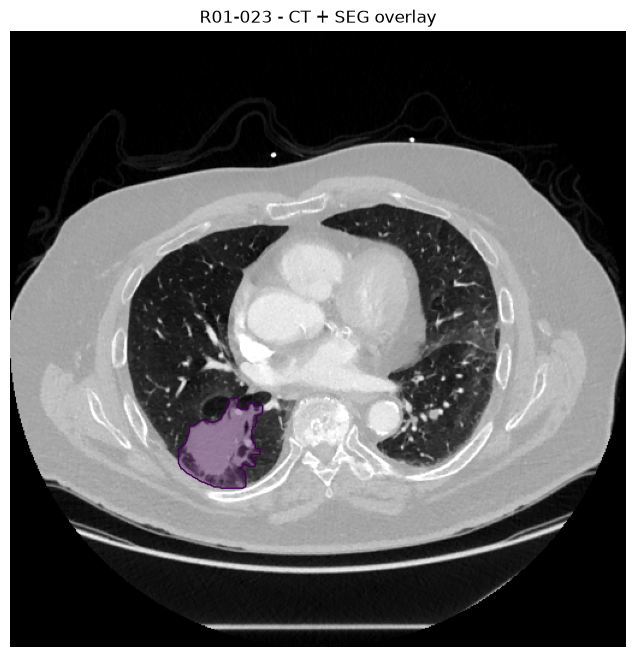

In [44]:
plt.figure(figsize=(8, 8))

plt.imshow(ct_hu, cmap="gray", vmin=-1000, vmax=400)

plt.imshow(
    np.ma.masked_where(~mask, mask),
    alpha=0.35
)

plt.contour(mask, levels=[0.5], linewidths=1)

plt.title(f"{case_id} - CT + SEG overlay")
plt.axis("off")
plt.show()

CT folder: F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01-133\10-31-1995-NA-ThoraxCHESTCONTRAST Adult-60655\3.000000-Chest  1.0  B45f-20952
SEG file: F:\yingxiang2\data\raw\NSCLC Radiogenomics\R01-133\10-31-1995-NA-ThoraxCHESTCONTRAST Adult-60655\1000.000000-ePAD Generated DSO Nov-11-2218-98040\1-1.dcm
SEG shape: (39, 512, 512)
SEG unique values: [0 1]
Non-zero voxels: 54547
SEG frames: 39
Referenced CT slices: 39
Max SEG frame index: 22
Mask area (pixels): 2838
CT file: 1-225.dcm


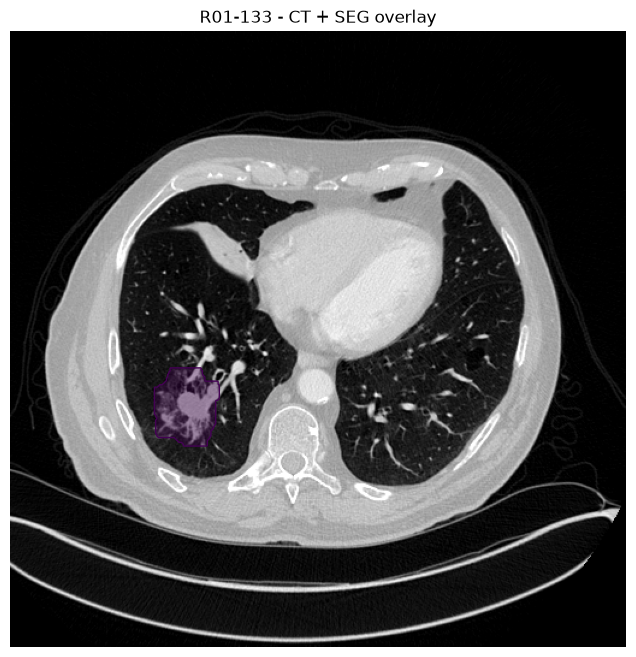

In [45]:
case_id = "R01-133"

# 读取该患者匹配的 CT 和 SEG 路径
row = match_qc_df.loc[match_qc_df["Case ID"] == case_id].iloc[0]

ct_folder = Path(row["Matched CT folder"])
seg_file = Path(row["SEG file"])

print("CT folder:", ct_folder)
print("SEG file:", seg_file)

# -----------------------------
# 读取 SEG
# -----------------------------
seg_ds = pydicom.dcmread(seg_file)
seg_array = seg_ds.pixel_array

print("SEG shape:", seg_array.shape)
print("SEG unique values:", np.unique(seg_array))
print("Non-zero voxels:", int((seg_array > 0).sum()))

# -----------------------------
# 建立 CT SOPInstanceUID -> 文件路径映射
# -----------------------------
ct_files = sorted([f for f in ct_folder.iterdir() if f.is_file()])

ct_uid_to_file = {}

for f in ct_files:
    ds = pydicom.dcmread(f, stop_before_pixels=True)
    ct_uid_to_file[str(ds.SOPInstanceUID)] = f

# -----------------------------
# 提取每个 SEG frame 引用的 CT SOPInstanceUID
# -----------------------------
frame_ref_uids = []

for frame_fg in seg_ds.PerFrameFunctionalGroupsSequence:
    uid = None

    if hasattr(frame_fg, "DerivationImageSequence"):
        deriv = frame_fg.DerivationImageSequence[0]

        if hasattr(deriv, "SourceImageSequence"):
            src = deriv.SourceImageSequence[0]
            uid = str(getattr(src, "ReferencedSOPInstanceUID", ""))

    frame_ref_uids.append(uid)

print("SEG frames:", len(frame_ref_uids))
print(
    "Referenced CT slices:",
    sum(uid in ct_uid_to_file for uid in frame_ref_uids)
)

# -----------------------------
# 找到 mask 面积最大的 frame
# -----------------------------
frame_areas = (seg_array > 0).sum(axis=(1, 2))
max_frame_idx = int(np.argmax(frame_areas))

max_uid = frame_ref_uids[max_frame_idx]
ct_file = ct_uid_to_file[max_uid]

mask = seg_array[max_frame_idx] > 0

print("Max SEG frame index:", max_frame_idx)
print("Mask area (pixels):", int(mask.sum()))
print("CT file:", ct_file.name)

# -----------------------------
# 读取对应 CT
# -----------------------------
ct_ds = pydicom.dcmread(ct_file)

ct_img = ct_ds.pixel_array.astype(float)

slope = float(getattr(ct_ds, "RescaleSlope", 1))
intercept = float(getattr(ct_ds, "RescaleIntercept", 0))

ct_hu = ct_img * slope + intercept

# -----------------------------
# CT + SEG overlay
# -----------------------------
plt.figure(figsize=(8, 8))

plt.imshow(
    ct_hu,
    cmap="gray",
    vmin=-1000,
    vmax=400
)

plt.imshow(
    np.ma.masked_where(~mask, mask),
    alpha=0.35
)

plt.contour(
    mask,
    levels=[0.5],
    linewidths=1
)

plt.title(f"{case_id} - CT + SEG overlay")
plt.axis("off")
plt.show()

In [46]:
final_qc_df = match_qc_df.copy()

final_qc_df["AIM_available"] = final_qc_df["Case ID"].isin(r01_aim_matched)

final_qc_df["Visual_QC"] = "Not required"
final_qc_df.loc[final_qc_df["Case ID"] == "R01-023", "Visual_QC"] = "PASS"
final_qc_df.loc[final_qc_df["Case ID"] == "R01-133", "Visual_QC"] = "PASS"

FINAL_QC_OUTPUT = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "final_cohort_qc.csv"
)

final_qc_df.to_csv(FINAL_QC_OUTPUT, index=False)

print(FINAL_QC_OUTPUT)
print("Exists:", FINAL_QC_OUTPUT.exists())

F:\yingxiang2\results\metrics\final_cohort_qc.csv
Exists: True
